# ERA5 trên lưới 0,05° — chất lượng dữ liệu sau khi lấy mẫu lại

Dữ liệu: `/home/slow_data/Air_Quality/ERA5/grid_005/era5_005_YYYY.nc` do `pm25_map/features/build_grid/map_era5_grid.py` sinh ra
từ các file giờ `ERA5/_monthly_raw/era5_YYYYMM.nc` (0,25°, UTC).

- Gộp theo **ngày địa phương UTC+7** trên lưới 0,25° rồi **bilinear** lên 310 × 160 ô 0,05° (cùng lưới với PM2.5 / MODIS).
- Hai cửa sổ: `_ovp` = 09–16 giờ địa phương (8 giờ, quanh giờ vệ tinh), `_24h` = 00–23 giờ. `Precip` là **tổng**, biến khác là **trung bình**.
- 11 biến: T2m (°C), RH (%), Psfc (hPa), **U10, V10** (m/s — thành phần đông/bắc của gió 10 m), PBLH (m), CloudCover (%), TCWV (kg/m²), SolarRad (W/m²), Precip (mm), CAPE (J/kg).
- Gió: TB ngày của U, V là gió **tổng hợp (véc-tơ)** → tốc độ suy ra `hypot(U, V)` ≤ TB tốc độ từng giờ; hướng (từ đâu thổi tới) = (270° − atan2(V, U)) mod 360.

Mục lục: 1. Tổng quan · 2. Kiểm tra giá trị · 3. Bản đồ trung bình · 4. Gió và hướng gió · 5. Chu kỳ năm theo vùng ·
6. `_ovp` so với `_24h` · 7. Độ mượt do lấy mẫu lại · 8. Tương quan giữa các biến · 9. Quan hệ với PM2.5 theo ngày · 10. Tóm tắt

> 25/10/2026: SolarRad, Precip đã sửa (tải lại `ssrd`, `tp`; bỏ bước lấy hiệu sai trong `fetch_era5_bbox.py`) — xem mục 10.

## 0. Thiết lập

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import glob
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, xarray as xr
import matplotlib.pyplot as plt

REPO = Path("/home/work1/projects/Air_Quality")
GRID_DIR = Path("/home/slow_data/Air_Quality/ERA5/grid_005")
PM_FILE = Path("/home/slow_data/Air_Quality/AQI/process/aqi_pm25_grid_daily.pkl")
NLAT, NLON, RES = 310, 160, 0.05
G = gpd.read_file(REPO / "pm25_map/output/vn_grid_005deg.gpkg", layer="grid").sort_values("cell_id").reset_index(drop=True)
LAND = G.in_vietnam.values.reshape(NLAT, NLON).astype(bool)
LI = np.flatnonzero(LAND.ravel()); REG_L = G.region.values[LI]
LATS = 23.5 - (np.arange(NLAT) + 0.5) * RES; LONS = 102 + (np.arange(NLON) + 0.5) * RES
PROV = gpd.read_file(REPO / "Data_Collection/GADM_Vietnam/gadm41_VNM_1.shp").to_crs("EPSG:4326")
REGION_ORDER = ["NW", "NE", "RRD", "NCC", "SCC", "CH", "SE"]
REGION_COLORS = {"NW": "#1f77b4", "NE": "#9467bd", "RRD": "#2ca02c", "NCC": "#bcbd22", "SCC": "#ff7f0e", "CH": "#8c564b", "SE": "#d62728"}
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM", 6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
VARS = ["T2m", "RH", "Psfc", "U10", "V10", "PBLH", "CloudCover", "TCWV", "SolarRad", "Precip", "CAPE"]
UNITS = {"T2m": "°C", "RH": "%", "Psfc": "hPa", "U10": "m/s", "V10": "m/s", "PBLH": "m", "CloudCover": "%",
         "TCWV": "kg/m²", "SolarRad": "W/m²", "Precip": "mm/ngày", "CAPE": "J/kg"}
FILES = {int(Path(f).stem[-4:]): f for f in sorted(glob.glob(str(GRID_DIR / "era5_005_????.nc")))}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

def vn_map(ax, arr, title, cmap="viridis", vmin=None, vmax=None, label=""):
    im = ax.imshow(arr, extent=[102, 110, 8, 23.5], origin="upper", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="none")
    PROV.boundary.plot(ax=ax, color="0.25", lw=0.25)
    ax.set_xlim(102, 110); ax.set_ylim(8, 23.5); ax.set_aspect(1 / np.cos(np.radians(16))); ax.grid(False)
    ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, shrink=0.55, label=label)
    return im

def wdir(u, v):
    """Hướng gió khí tượng (độ, từ đâu thổi tới; 0 = bắc, 90 = đông)."""
    return (270 - np.degrees(np.arctan2(v, u))) % 360

print("Năm:", list(FILES), "· ô đất liền:", len(LI))
with xr.open_dataset(FILES[max(FILES)]) as ds:
    print("Biến trong file:", [v for v in ds.data_vars if v != "cell_id"])
    print("Thuộc tính:", {k: ds.attrs[k] for k in ("resampling", "windows")})

Năm: [2020, 2021, 2022, 2023, 2024, 2025, 2026] · ô đất liền: 11206
Biến trong file: ['n_hours_ovp', 'n_hours_24h', 'T2m_ovp', 'T2m_24h', 'RH_ovp', 'RH_24h', 'Psfc_ovp', 'Psfc_24h', 'U10_ovp', 'U10_24h', 'V10_ovp', 'V10_24h', 'PBLH_ovp', 'PBLH_24h', 'CloudCover_ovp', 'CloudCover_24h', 'TCWV_ovp', 'TCWV_24h', 'SolarRad_ovp', 'SolarRad_24h', 'Precip_ovp', 'Precip_24h', 'CAPE_ovp', 'CAPE_24h']
Thuộc tính: {'resampling': 'bilinear from ERA5 0.25 deg; daily aggregation done on the native grid first', 'windows': 'ovp: 09-16 LT; 24h: 00-23 LT'}


In [2]:
# Đọc: mảng ô đất liền (24h + vài biến ovp) cho phân tích; tích luỹ toàn miền cho bản đồ
L24 = {v: [] for v in VARS}; LOV = {v: [] for v in ("T2m", "RH", "PBLH", "U10", "V10", "CloudCover")}
N2 = NLAT * NLON
macc = {v: np.zeros(N2) for v in VARS}; nacc = 0
sacc = {s: {v: np.zeros(N2) for v in ("U10", "V10", "T2m", "Precip", "PBLH")} | {"n": 0} for s in ("DJF", "MAM", "JJA", "SON")}
dates, nh = [], []
for y, f in FILES.items():
    with xr.open_dataset(f) as ds:
        dd = pd.to_datetime(ds.date.values)
        has = (ds.n_hours_24h.values > 0)
        dd = dd[has]; nh.append(pd.DataFrame({"ovp": ds.n_hours_ovp.values[has], "h24": ds.n_hours_24h.values[has]}, index=dd))
        sm = np.asarray(dd.month.map(SEASON))
        for v in VARS:
            a = ds[f"{v}_24h"].values[has].reshape(len(dd), -1)
            macc[v] += np.nansum(a, 0); L24[v].append(a[:, LI])
            for s in sacc:
                if v in sacc[s]: sacc[s][v] += np.nansum(a[sm == s], 0)
        for v in LOV:
            LOV[v].append(ds[f"{v}_ovp"].values[has].reshape(len(dd), -1)[:, LI])
    nacc += len(dd); dates.append(dd)
    for s in sacc: sacc[s]["n"] += int((sm == s).sum())
DATES = pd.DatetimeIndex(np.concatenate(dates)); NH = pd.concat(nh)
L24 = {v: np.vstack(x) for v, x in L24.items()}; LOV = {v: np.vstack(x) for v, x in LOV.items()}
MEAN = {v: (macc[v] / nacc).reshape(NLAT, NLON) for v in VARS}
print(f"{len(DATES):,} ngày ({DATES.min().date()} → {DATES.max().date()}) · mảng đất liền {L24['T2m'].shape}")

2,349 ngày (2020-01-01 → 2026-06-06) · mảng đất liền (2349, 11206)


## 1. Tổng quan

In [3]:
ov = NH.groupby(NH.index.year).agg(ngay=("h24", "size"), du_24h=("h24", lambda x: (x == 24).sum()), du_ovp=("ovp", lambda x: (x == 8).sum()),
                                     thieu_24h=("h24", lambda x: ((x > 0) & (x < 24)).sum()))
ov["đến ngày"] = [DATES[DATES.year == y].max().date() for y in ov.index]
display(ov)
print("Ngày thiếu giờ:", NH[NH.h24 < 24].assign(h24=lambda x: x.h24).h24.to_dict())
miss = pd.date_range(DATES.min(), DATES.max()).difference(DATES)
print(f"Ngày trống trong khoảng dữ liệu: {len(miss)}")

,ngay,du_24h,du_ovp,thieu_24h,đến ngày
2020,366,365,366,1,2020-12-31
2021,365,365,365,0,2021-12-31
2022,365,365,365,0,2022-12-31
2023,365,365,365,0,2023-12-31
2024,366,366,366,0,2024-12-31
2025,365,365,365,0,2025-12-31
2026,157,156,156,1,2026-06-06


Ngày thiếu giờ: {Timestamp('2020-01-01 00:00:00'): 17, Timestamp('2026-06-06 00:00:00'): 16}
Ngày trống trong khoảng dữ liệu: 0


## 2. Kiểm tra giá trị (ô đất liền-ngày, cửa sổ 24h)

,đơn vị,NaN %,min,p1,trung vị,p99,max,ngoài khoảng hợp lý
biến,,,,,,,,
T2m,°C,0.0,2.46,11.71,25.24,31.49,36.41,0
RH,%,0.0,31.93,56.19,82.75,96.06,100.00,0
Psfc,hPa,0.0,853.75,883.43,972.91,1016.79,1031.87,0
U10,m/s,0.0,-15.29,-4.58,-0.41,4.21,15.36,0
V10,m/s,0.0,-15.63,-4.79,0.18,3.35,14.74,0
PBLH,m,0.0,31.58,139.36,414.73,1001.26,1600.88,0
CloudCover,%,0.0,0.00,4.66,80.42,100.00,100.00,0
TCWV,kg/m²,0.0,4.60,13.99,44.48,66.06,80.23,0
SolarRad,W/m²,0.0,7.09,30.85,196.57,304.11,386.84,0


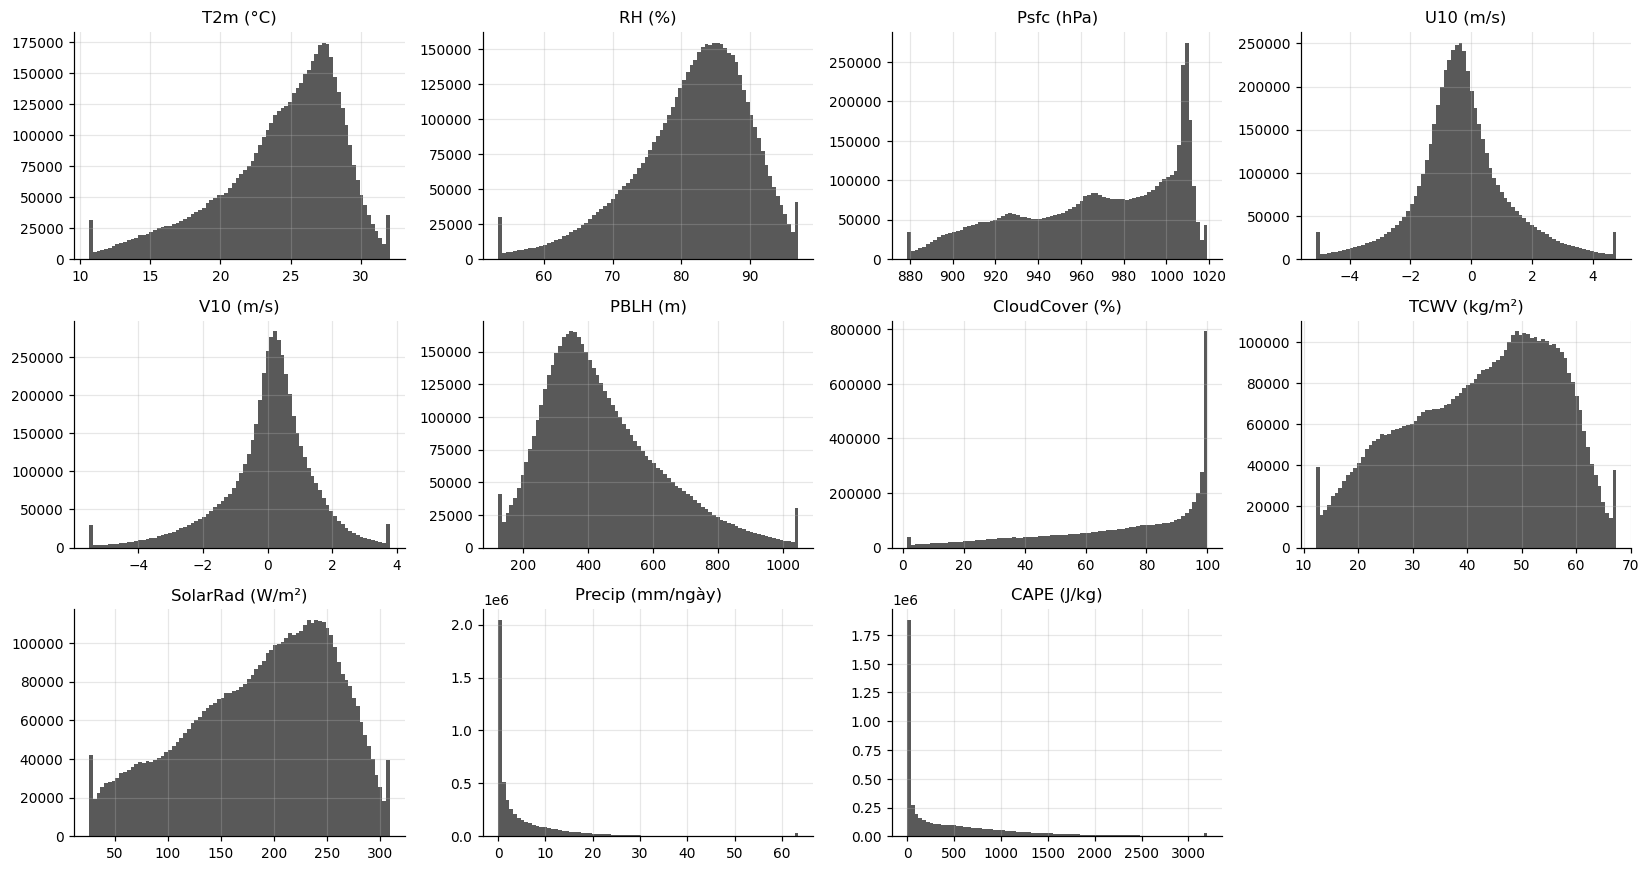

In [4]:
LIMITS = {"T2m": (-15, 45), "RH": (0, 100.0001), "Psfc": (600, 1050), "U10": (-30, 30), "V10": (-30, 30), "PBLH": (0, 6000),
          "CloudCover": (0, 100.0001), "TCWV": (0, 90), "SolarRad": (0, 1400), "Precip": (0, 1000), "CAPE": (0, 8000)}
rows = []
for v in VARS:
    a = L24[v]; f = np.isfinite(a); lo, hi = LIMITS[v]
    rows.append({"biến": v, "đơn vị": UNITS[v], "NaN %": round(100 * (~f).mean(), 4), "min": round(float(np.nanmin(a)), 2),
                 "p1": round(float(np.nanpercentile(a, 1)), 2), "trung vị": round(float(np.nanmedian(a)), 2),
                 "p99": round(float(np.nanpercentile(a, 99)), 2), "max": round(float(np.nanmax(a)), 2),
                 "ngoài khoảng hợp lý": int(((a < lo) | (a > hi))[f].sum())})
display(pd.DataFrame(rows).set_index("biến"))
fig, axs = plt.subplots(3, 4, figsize=(15, 8)); axs = axs.ravel()
for ax, v in zip(axs, VARS):
    a = L24[v][::5].ravel(); a = a[np.isfinite(a)]; lo, hi = np.percentile(a, [0.5, 99.5])
    ax.hist(np.clip(a, lo, hi), bins=80, color="0.35"); ax.set_title(f"{v} ({UNITS[v]})")
axs[-1].axis("off"); plt.tight_layout(); plt.show()

## 3. Bản đồ trung bình nhiều năm (cửa sổ 24h)

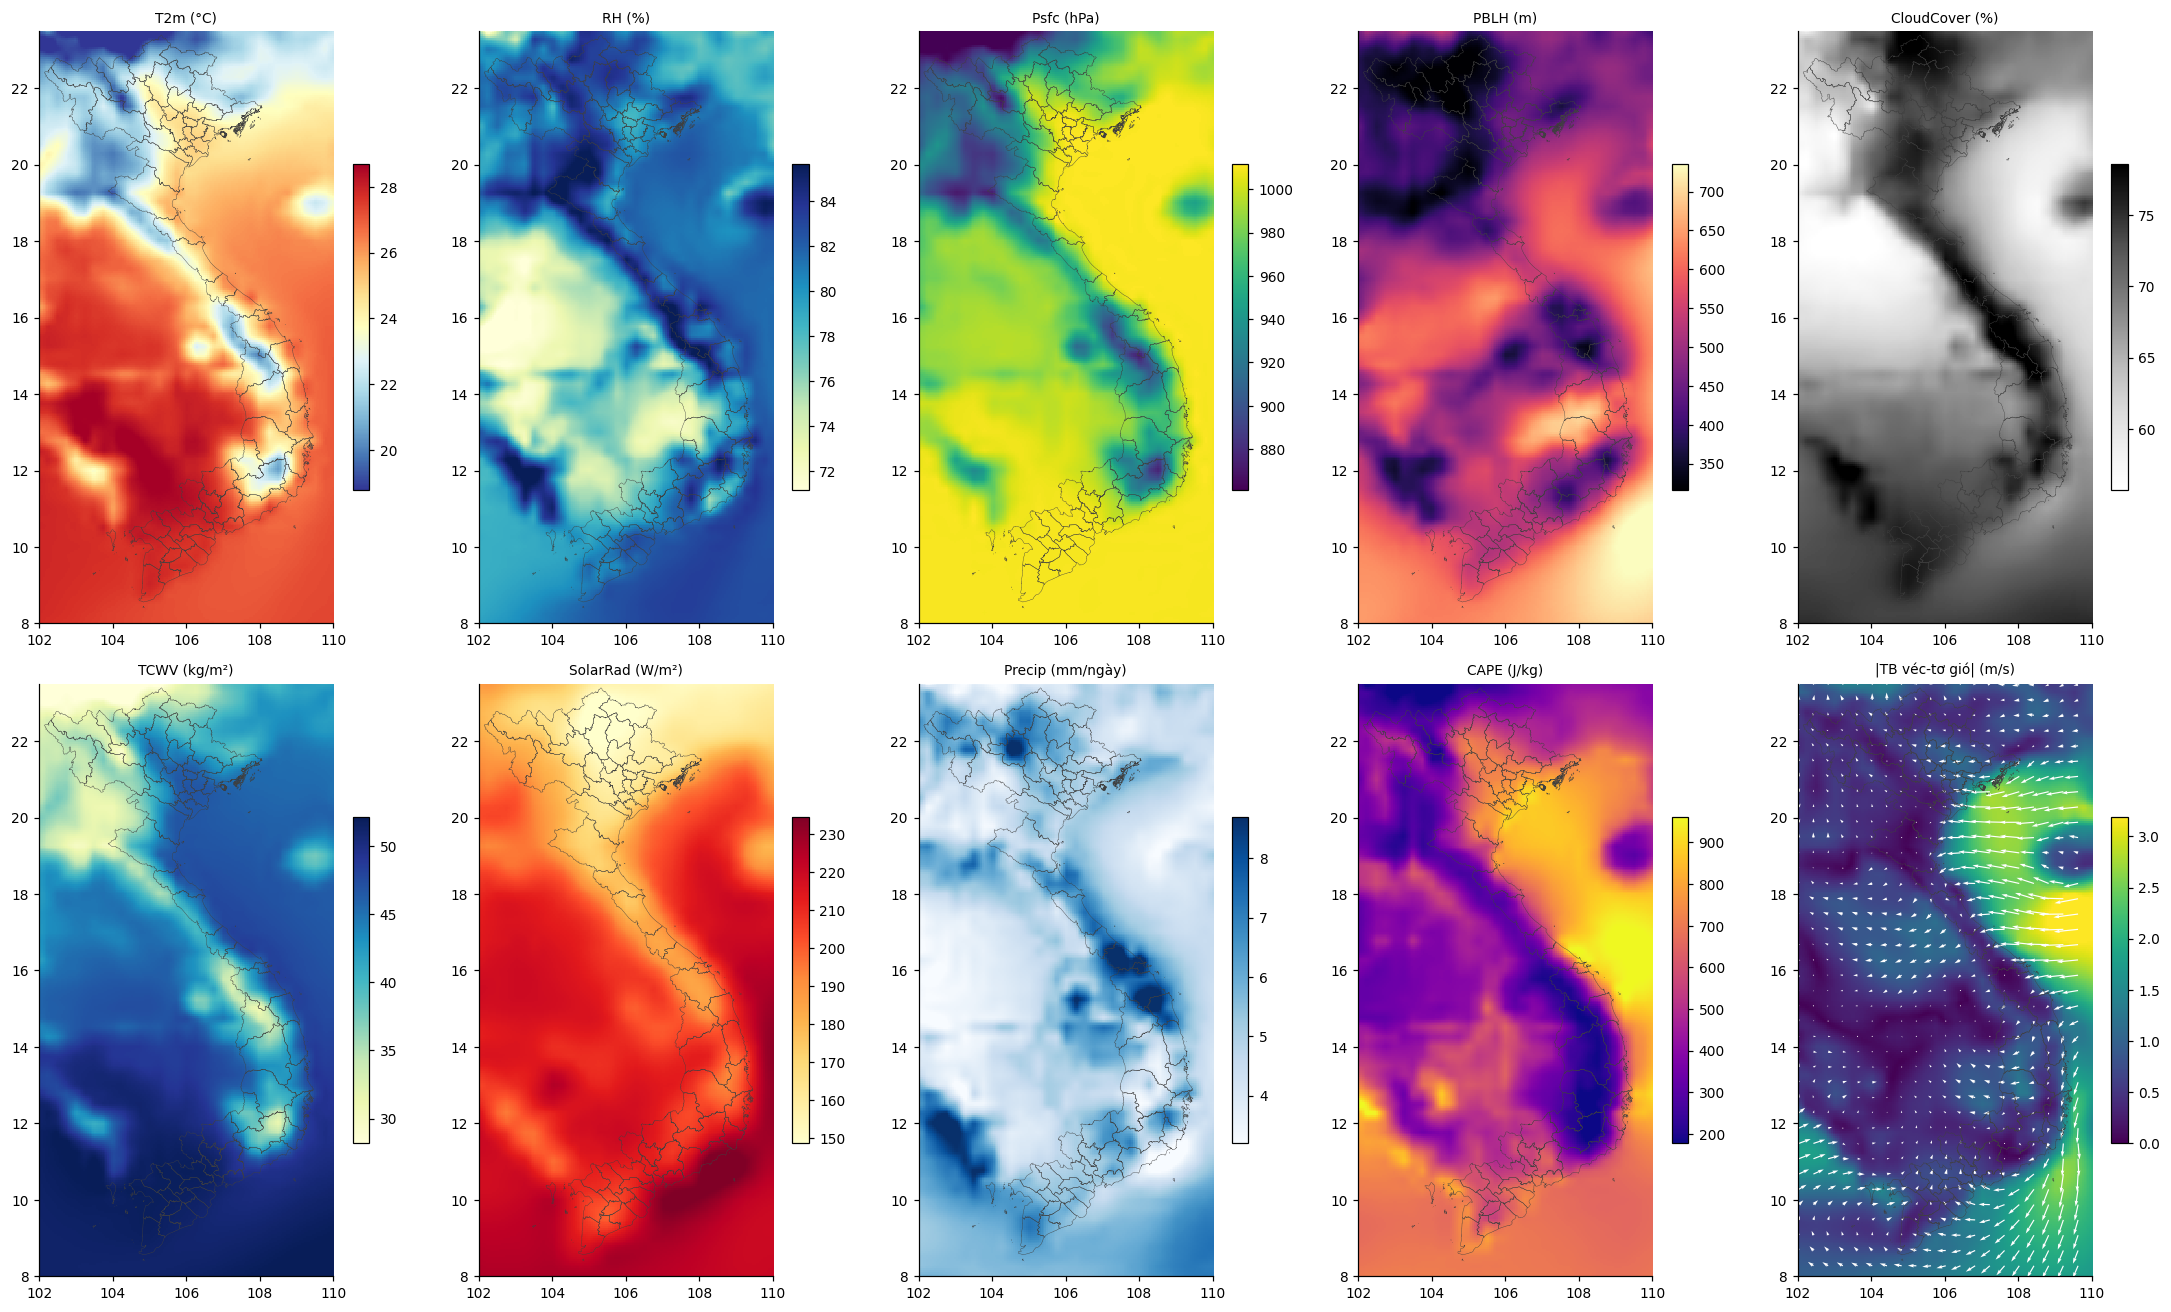

In [5]:
cm = {"T2m": "RdYlBu_r", "RH": "YlGnBu", "Psfc": "viridis", "PBLH": "magma", "CloudCover": "Greys", "TCWV": "YlGnBu",
      "SolarRad": "YlOrRd", "Precip": "Blues", "CAPE": "plasma"}
vs = [v for v in VARS if v not in ("U10", "V10")]
fig, axs = plt.subplots(2, 5, figsize=(20, 12)); axs = axs.ravel()
for ax, v in zip(axs, vs):
    lo, hi = np.nanpercentile(MEAN[v], [1, 99]); vn_map(ax, MEAN[v], f"{v} ({UNITS[v]})", cm.get(v, "viridis"), lo, hi)
ws = np.hypot(MEAN["U10"], MEAN["V10"]); vn_map(axs[-1], ws, "|TB véc-tơ gió| (m/s)", "viridis", 0, np.nanpercentile(ws, 99))
k = 8; axs[-1].quiver(LONS[::k], LATS[::k], MEAN["U10"][::k, ::k], MEAN["V10"][::k, ::k], color="w", scale=40, width=0.004)
plt.tight_layout(); plt.show()

## 4. Gió và hướng gió
Việt Nam có hai mùa gió: **gió mùa đông bắc** (khoảng tháng 11–3) và **gió mùa tây nam** (khoảng tháng 5–9). Hướng gió quyết định không khí ô nhiễm được mang tới từ đâu (đồng bằng sông Hồng, Trung Quốc, khói đốt Lào/Myanmar...).

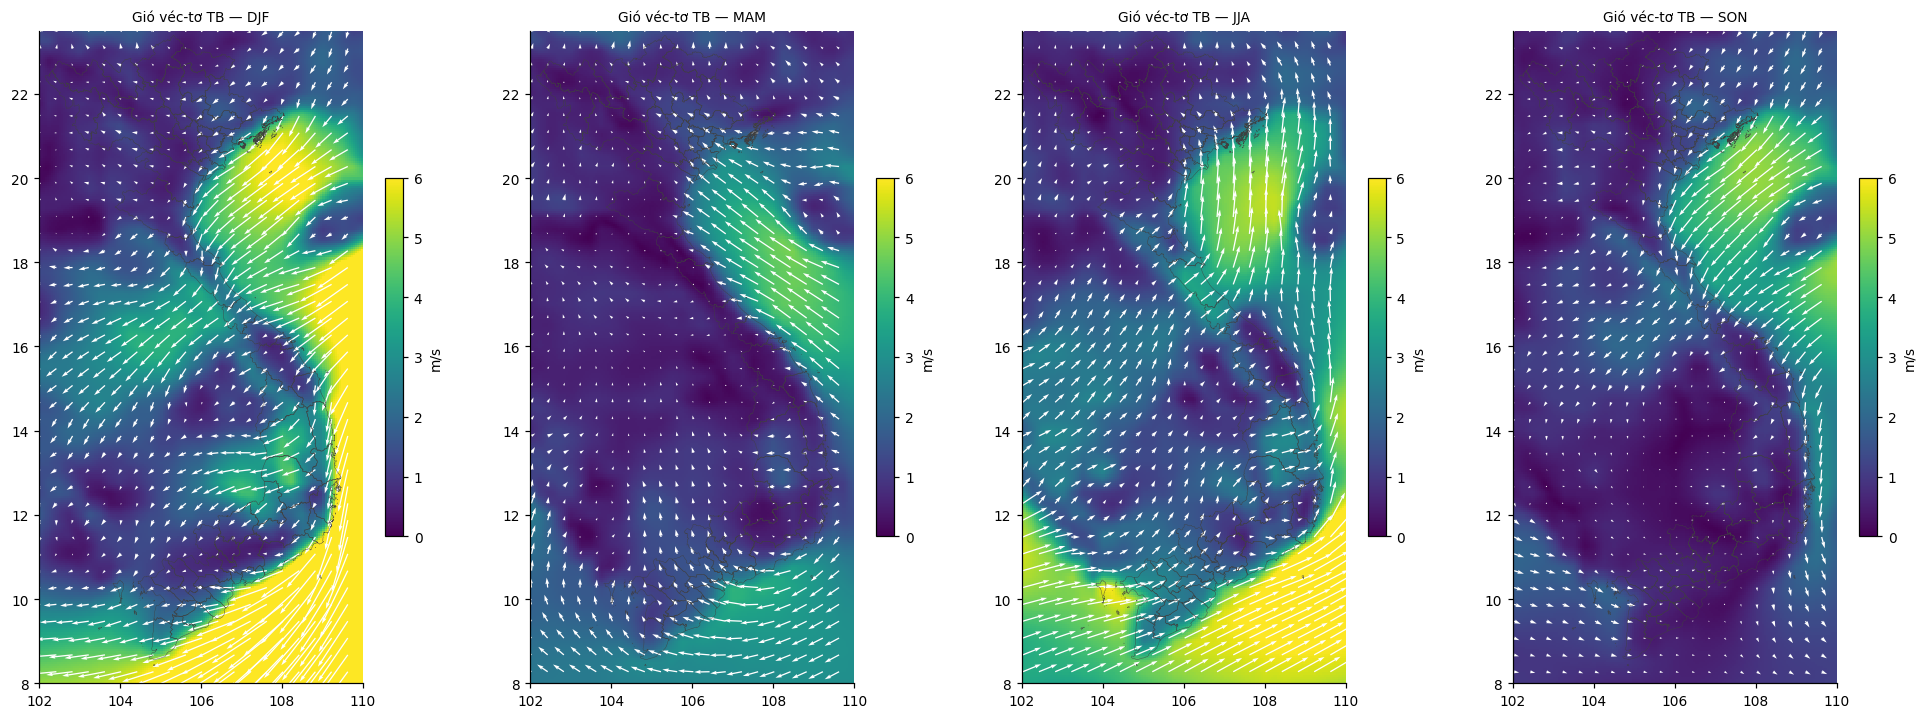

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(18, 6.5))
for ax, s in zip(axs, sacc):
    u = sacc[s]["U10"].reshape(NLAT, NLON) / sacc[s]["n"]; v = sacc[s]["V10"].reshape(NLAT, NLON) / sacc[s]["n"]
    vn_map(ax, np.hypot(u, v), f"Gió véc-tơ TB — {s}", "viridis", 0, 6, "m/s")
    k = 8; ax.quiver(LONS[::k], LATS[::k], u[::k, ::k], v[::k, ::k], color="w", scale=60, width=0.004)
plt.tight_layout(); plt.show()

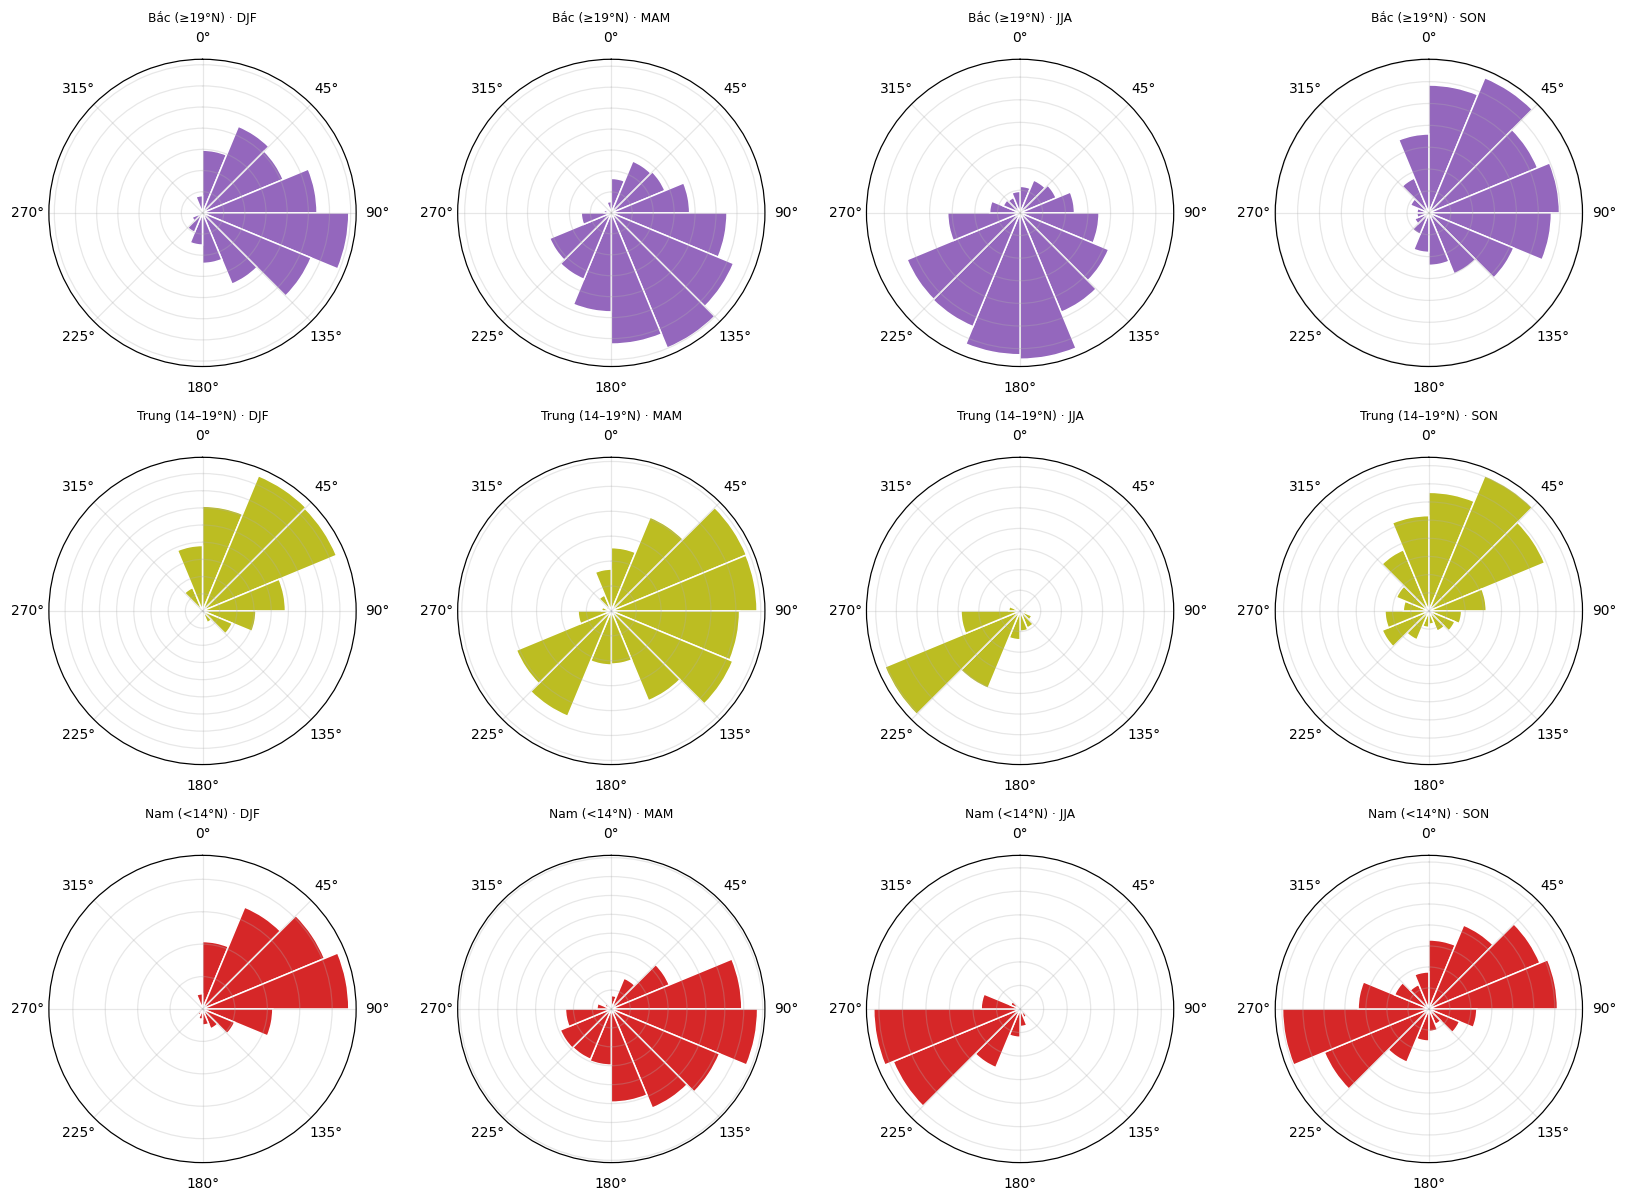

Tốc độ gió véc-tơ ngày (ô đất liền): trung vị 1.43 m/s, p95 4.42 m/s


In [7]:
# Phân bố hướng gió theo mùa và theo 3 dải vĩ độ (ô đất liền-ngày, 24h)
band = np.where(G.lat.values[LI] >= 19, "Bắc (≥19°N)", np.where(G.lat.values[LI] >= 14, "Trung (14–19°N)", "Nam (<14°N)"))
D = wdir(L24["U10"], L24["V10"]); SP_ = np.hypot(L24["U10"], L24["V10"])
sm = np.asarray(DATES.month.map(SEASON))
bins = np.arange(0, 361, 22.5); centers = np.radians(bins[:-1] + 11.25)
fig, axs = plt.subplots(3, 4, figsize=(15, 11), subplot_kw={"projection": "polar"})
for i, b in enumerate(("Bắc (≥19°N)", "Trung (14–19°N)", "Nam (<14°N)")):
    for j, s in enumerate(("DJF", "MAM", "JJA", "SON")):
        x = D[sm == s][:, band == b][::3].ravel(); x = x[np.isfinite(x)]
        h, _ = np.histogram(x, bins=bins); ax = axs[i, j]
        ax.bar(centers, h / h.sum(), width=np.radians(22.5), color=REGION_COLORS["SE" if "Nam" in b else ("NCC" if "Trung" in b else "NE")], edgecolor="w")
        ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([]); ax.set_title(f"{b} · {s}", fontsize=8)
plt.tight_layout(); plt.show()
print("Tốc độ gió véc-tơ ngày (ô đất liền): trung vị %.2f m/s, p95 %.2f m/s" % (np.nanmedian(SP_), np.nanpercentile(SP_, 95)))

## 5. Chu kỳ năm theo vùng

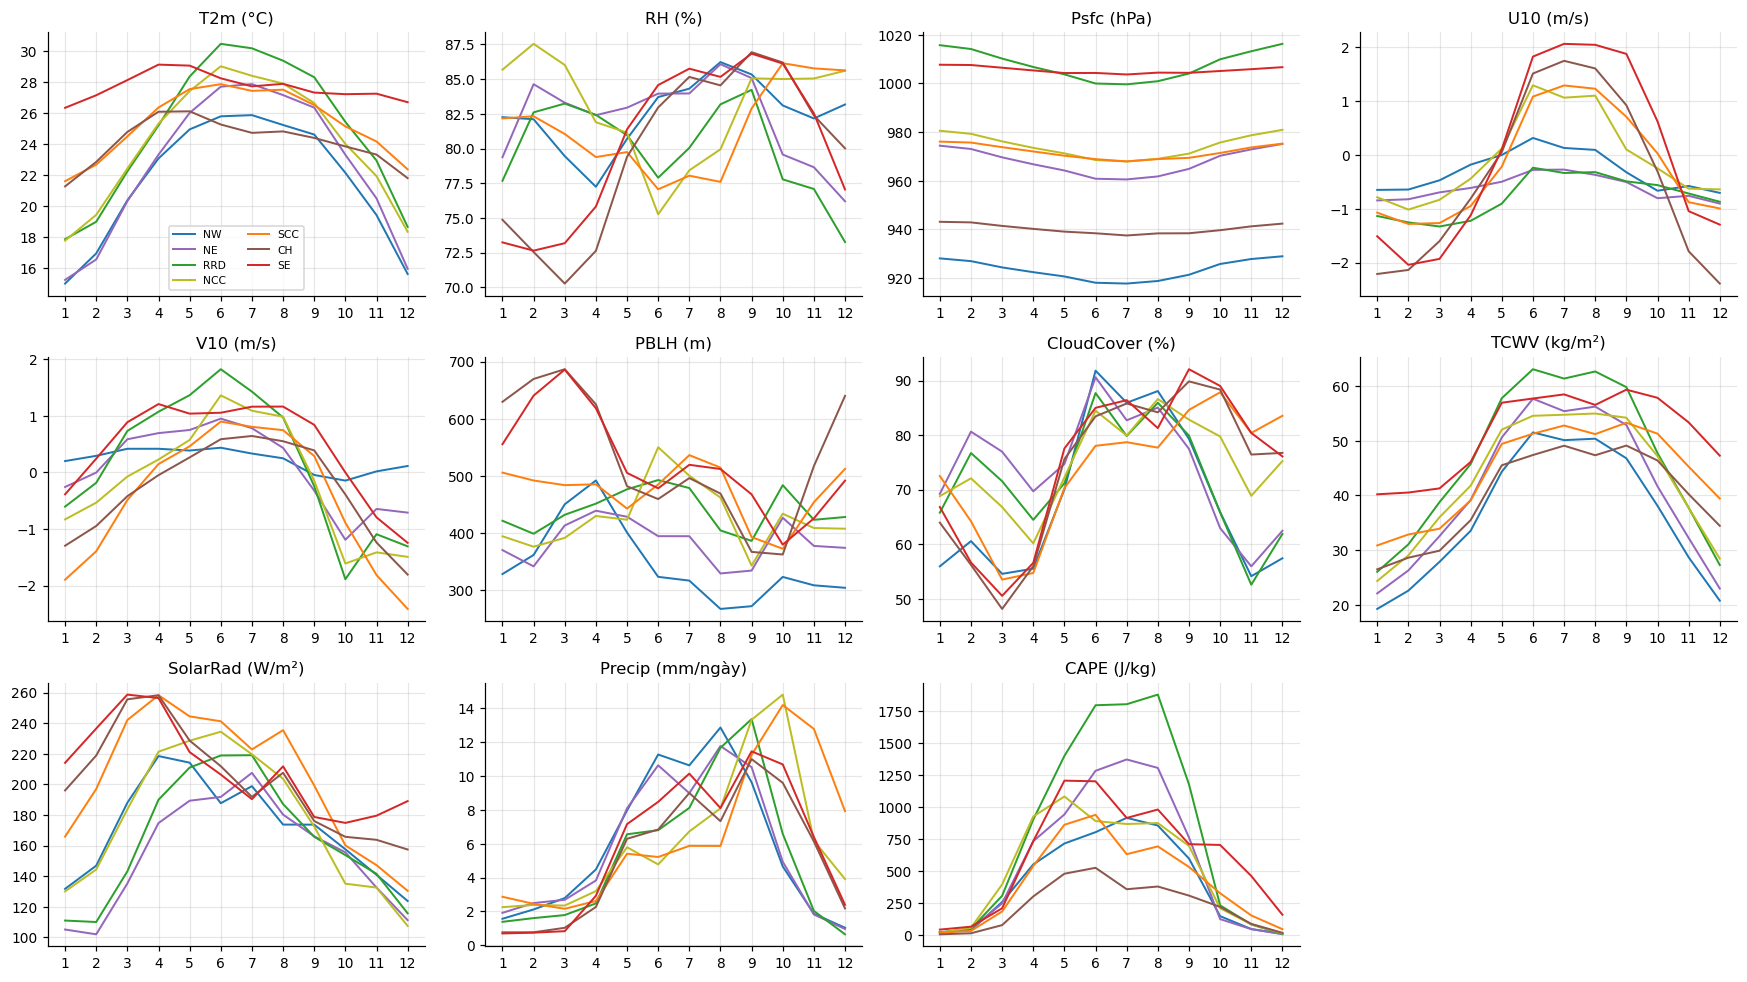

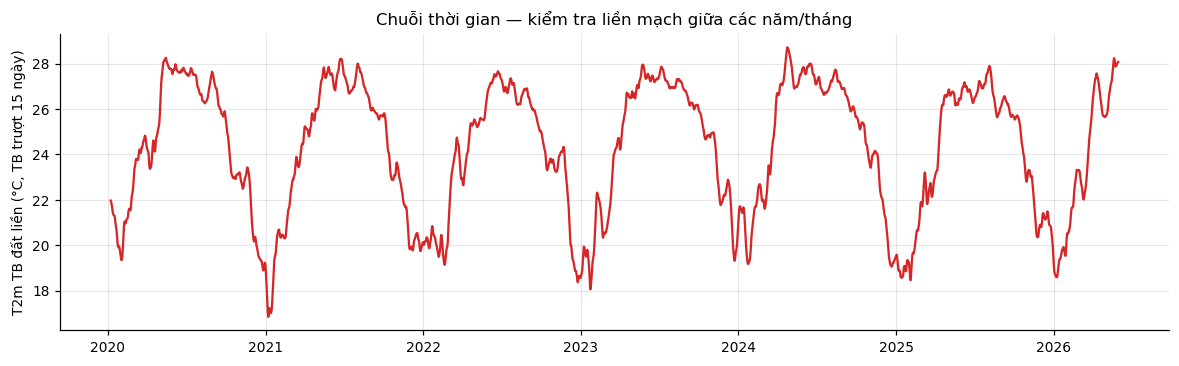

TB năm theo vùng (T2m °C):


,NW,NE,RRD,NCC,SCC,CH,SE
2020,21.440001,22.350000,24.860001,24.309999,25.540001,24.430000,27.770000
2021,21.379999,22.480000,24.809999,23.870001,25.139999,23.850000,27.299999
2022,21.170000,22.020000,24.280001,23.620001,25.020000,23.910000,27.500000
2023,21.980000,22.820000,25.080000,24.309999,25.480000,24.120001,27.730000
2024,22.129999,22.910000,25.200001,24.510000,25.820000,24.680000,28.260000
2025,21.240000,22.290001,24.440001,23.440001,24.920000,23.730000,27.570000
2026,20.950001,21.540001,23.980000,23.530001,24.600000,24.100000,27.879999


In [8]:
reg = {v: pd.DataFrame({r: np.nanmean(L24[v][:, REG_L == r], axis=1) for r in REGION_ORDER}, index=DATES) for v in VARS}
fig, axs = plt.subplots(3, 4, figsize=(16, 9)); axs = axs.ravel()
for ax, v in zip(axs, VARS):
    reg[v].groupby(reg[v].index.month).mean().plot(ax=ax, color=[REGION_COLORS[r] for r in REGION_ORDER], legend=False, lw=1.3)
    ax.set_title(f"{v} ({UNITS[v]})"); ax.set_xticks(range(1, 13)); ax.set_xlabel("")
axs[-1].axis("off"); axs[0].legend(REGION_ORDER, fontsize=7, ncol=2); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(13, 3.5))
for v, col in (("T2m", "#d62728"),):
    s_ = pd.Series(np.nanmean(L24[v], axis=1), index=DATES); ax.plot(s_.rolling(15, center=True).mean(), color=col)
ax.set_ylabel("T2m TB đất liền (°C, TB trượt 15 ngày)"); ax.set_title("Chuỗi thời gian — kiểm tra liền mạch giữa các năm/tháng"); plt.show()
print("TB năm theo vùng (T2m °C):"); display(reg["T2m"].groupby(reg["T2m"].index.year).mean().round(2))

## 6. Cửa sổ `_ovp` (09–16 giờ) so với `_24h`

T2m       : TB ovp    26.71 · TB 24h    24.27 · ovp − 24h trung vị    +2.47 · r 0.971
RH        : TB ovp    70.70 · TB 24h    81.33 · ovp − 24h trung vị   -10.77 · r 0.931
PBLH      : TB ovp   854.41 · TB 24h   452.17 · ovp − 24h trung vị  +380.21 · r 0.757
CloudCover: TB ovp    73.59 · TB 24h    72.75 · ovp − 24h trung vị    +0.16 · r 0.916


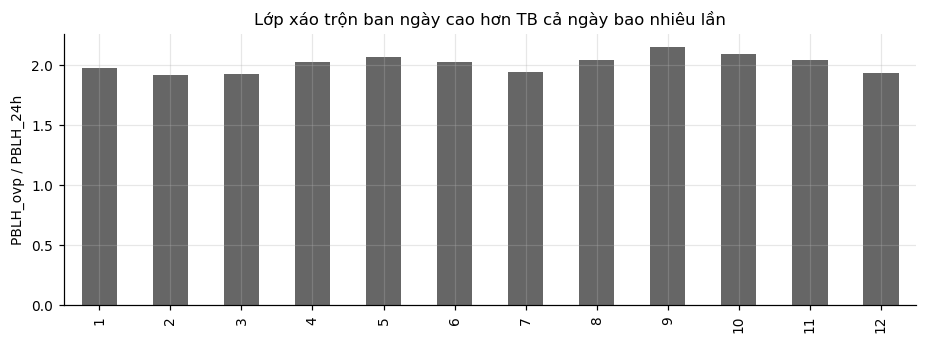

In [9]:
for v in ("T2m", "RH", "PBLH", "CloudCover"):
    a, b = LOV[v], L24[v]; d = a - b
    print(f"{v:10s}: TB ovp {np.nanmean(a):8.2f} · TB 24h {np.nanmean(b):8.2f} · ovp − 24h trung vị {np.nanmedian(d):+8.2f} · r {np.corrcoef(a[np.isfinite(a)&np.isfinite(b)], b[np.isfinite(a)&np.isfinite(b)])[0,1]:.3f}")
ratio = pd.Series(np.nanmedian(LOV["PBLH"] / L24["PBLH"], axis=1), index=DATES)
fig, ax = plt.subplots(figsize=(10, 3.2)); ratio.groupby(ratio.index.month).median().plot.bar(ax=ax, color="0.4")
ax.set_ylabel("PBLH_ovp / PBLH_24h"); ax.set_title("Lớp xáo trộn ban ngày cao hơn TB cả ngày bao nhiêu lần"); plt.show()

## 7. Độ mượt do lấy mẫu lại
ERA5 0,25° (độ phân giải hiệu dụng ~31 km) nội suy bilinear lên 0,05° **không thêm chi tiết nhỏ hơn 25 km**: hai ô liền nhau gần như luôn có giá trị gần nhau, và giá trị giữa hai điểm ERA5 là tuyến tính. Địa hình bị san phẳng (ô trên núi nhận T2m / Psfc của độ cao TB ô 0,25°).

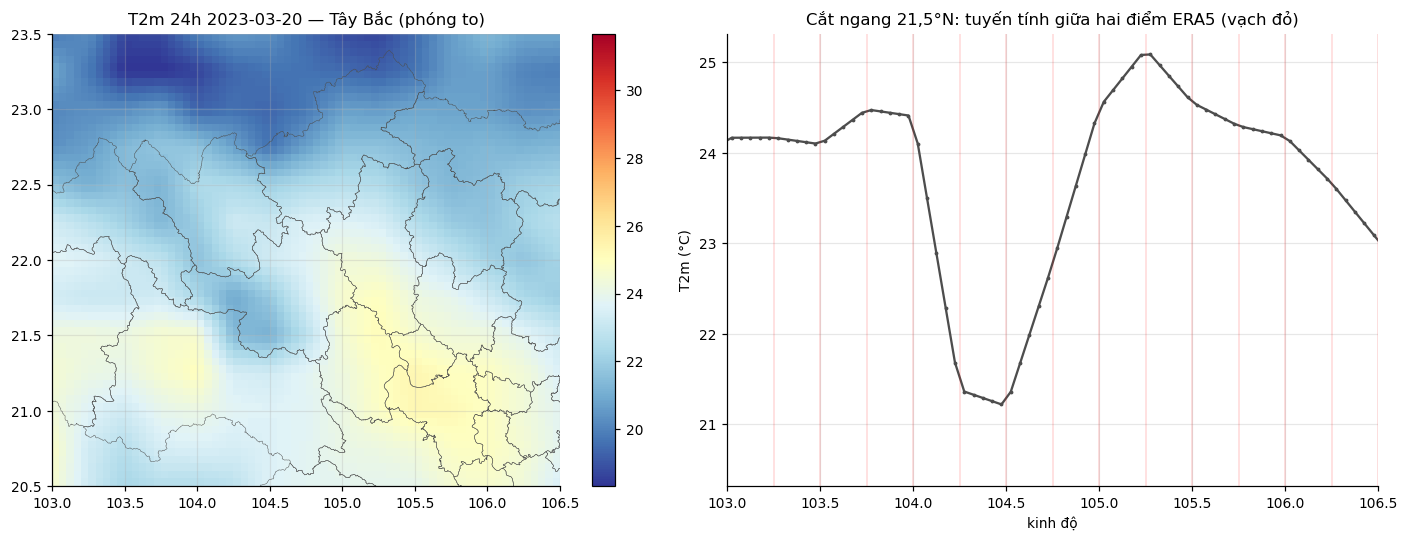

Chênh T2m TB nhiều năm giữa hai ô liền nhau (đất liền): trung vị 0.094 °C, p99 0.465 °C


In [10]:
day = DATES[len(DATES) // 2]
with xr.open_dataset(FILES[day.year]) as ds:
    t = ds["T2m_24h"].sel(date=day).values
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
im = axs[0].imshow(t, extent=[102, 110, 8, 23.5], origin="upper", cmap="RdYlBu_r"); PROV.boundary.plot(ax=axs[0], color="0.3", lw=0.3)
axs[0].set_xlim(103, 106.5); axs[0].set_ylim(20.5, 23.5); axs[0].set_title(f"T2m 24h {day.date()} — Tây Bắc (phóng to)"); plt.colorbar(im, ax=axs[0])
i = np.argmin(abs(LATS - 21.5)); axs[1].plot(LONS, t[i], ".-", ms=3, color="0.3")
for x in np.arange(102, 110.01, 0.25): axs[1].axvline(x, color="r", lw=0.3, alpha=0.5)
axs[1].set_xlim(103, 106.5); axs[1].set_xlabel("kinh độ"); axs[1].set_ylabel("T2m (°C)"); axs[1].set_title("Cắt ngang 21,5°N: tuyến tính giữa hai điểm ERA5 (vạch đỏ)")
plt.tight_layout(); plt.show()
g = np.abs(np.diff(MEAN["T2m"], axis=1))[LAND[:, 1:] & LAND[:, :-1]]
print(f"Chênh T2m TB nhiều năm giữa hai ô liền nhau (đất liền): trung vị {np.median(g):.3f} °C, p99 {np.percentile(g, 99):.3f} °C")

## 8. Tương quan giữa các biến (ô đất liền-ngày, 24h, mẫu)

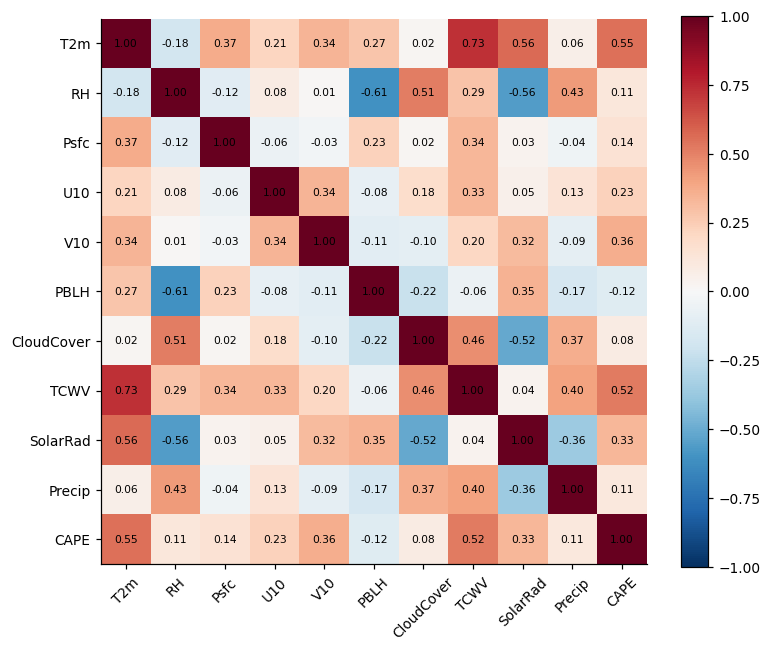

In [11]:
smp = pd.DataFrame({v: L24[v][::7].ravel() for v in VARS}).dropna().sample(300_000, random_state=0)
cc = smp.corr()
fig, ax = plt.subplots(figsize=(8, 6.5)); im = ax.imshow(cc, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(VARS)), VARS, rotation=45); ax.set_yticks(range(len(VARS)), VARS)
for (i, j), v in np.ndenumerate(cc.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax); plt.show()

## 9. Quan hệ với PM2.5 theo ngày
Cặp (ô có trạm × ngày) với PM2.5 đã QC (min-hours 8). Tương quan **trong cùng ô** (bỏ khác biệt giữa các nơi) giữa log PM2.5 và từng biến; và PM2.5 theo **hướng gió**.

In [12]:
pm = pd.read_pickle(PM_FILE)
rows = []
for y, f in FILES.items():
    sub = pm[pm.date.dt.year == y]
    if sub.empty: continue
    with xr.open_dataset(f) as ds:
        di = pd.Index(pd.to_datetime(ds.date.values)).get_indexer(sub.date); out = sub.copy()
        for v in VARS: out[v] = ds[f"{v}_24h"].values[di, sub.row.values, sub.col.values]
        for v in ("PBLH", "U10", "V10"): out[v + "_ovp"] = ds[f"{v}_ovp"].values[di, sub.row.values, sub.col.values]
    rows.append(out)
PE = pd.concat(rows, ignore_index=True).dropna(subset=VARS)
PE["lpm"] = np.log(PE.pm25); PE["WS"] = np.hypot(PE.U10, PE.V10); PE["WD"] = wdir(PE.U10, PE.V10)
PE["season"] = PE.date.dt.month.map(SEASON); PE["lat"] = PE.cell_lat
dmn = lambda c: PE[c] - PE.groupby("cell_id")[c].transform("mean")
cols = VARS + ["WS", "PBLH_ovp"]
r_in = {c: round(float(np.corrcoef(dmn(c), dmn("lpm"))[0, 1]), 3) for c in cols}
print(f"{len(PE):,} cặp ô-ngày ở {PE.cell_id.nunique()} ô · r(log PM2.5, biến) trong cùng ô:")
print(pd.Series(r_in).sort_values().to_string())

46,377 cặp ô-ngày ở 80 ô · r(log PM2.5, biến) trong cùng ô:
TCWV         -0.471
T2m          -0.316
CloudCover   -0.273
Precip       -0.262
CAPE         -0.248
WS           -0.240
RH           -0.203
PBLH         -0.189
V10          -0.109
U10          -0.040
SolarRad      0.005
PBLH_ovp      0.065
Psfc          0.331


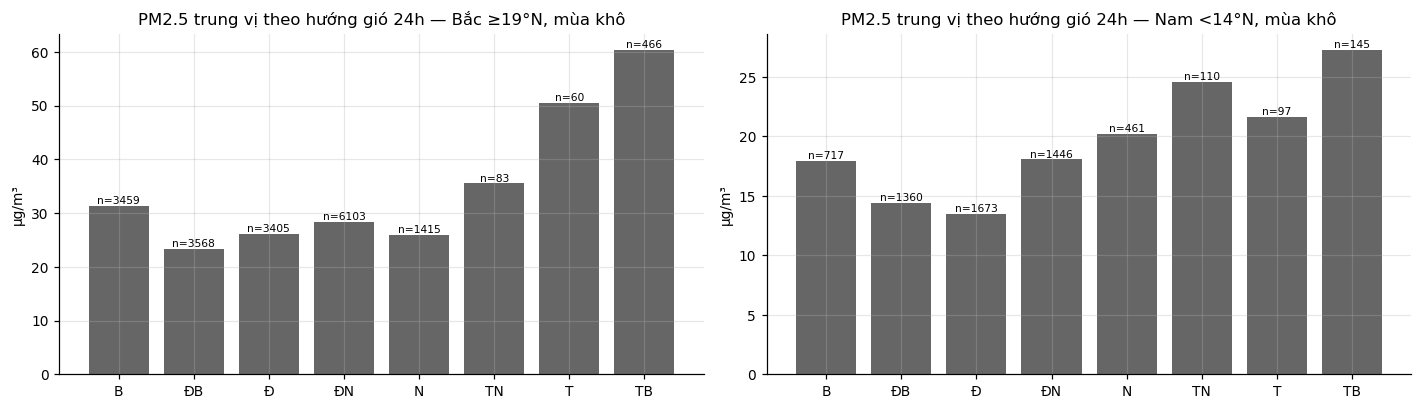

Miền Bắc mùa khô — trung vị PM2.5 theo hướng: {'B': 31.3, 'ĐB': 23.3, 'Đ': 26.2, 'ĐN': 28.3, 'N': 25.9, 'TN': 35.5, 'T': 50.5, 'TB': 60.3}
Miền Bắc mùa khô — trung vị PM2.5 theo tốc độ gió véc-tơ: {Interval(0, 1, closed='right'): 48.2, Interval(1, 2, closed='right'): 33.4, Interval(2, 3, closed='right'): 24.7, Interval(3, 4, closed='right'): 19.4, Interval(4, 20, closed='right'): 15.1}


In [13]:
# PM2.5 theo hướng gió (8 hướng), miền Bắc (≥ 19°N) và miền Nam (< 14°N), mùa khô (tháng 11–4)
sect = ["B", "ĐB", "Đ", "ĐN", "N", "TN", "T", "TB"]
PE["sector"] = pd.Categorical(np.array(sect)[((PE.WD + 22.5) // 45 % 8).astype(int)], categories=sect, ordered=True)
dry = PE.date.dt.month.isin([11, 12, 1, 2, 3, 4])
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (lab, m) in zip(axs, (("Bắc ≥19°N", PE.lat >= 19), ("Nam <14°N", PE.lat < 14))):
    x = PE[m & dry]; t = x.groupby("sector", observed=False).agg(pm=("pm25", "median"), n=("pm25", "size"))
    ax.bar(t.index.astype(str), t.pm, color="0.4")
    for i, (p_, n_) in enumerate(zip(t.pm, t.n)): ax.text(i, p_, f"n={n_}", ha="center", va="bottom", fontsize=7)
    ax.set_title(f"PM2.5 trung vị theo hướng gió 24h — {lab}, mùa khô"); ax.set_ylabel("µg/m³")
plt.tight_layout(); plt.show()
X = PE[(PE.lat >= 19) & dry]
print("Miền Bắc mùa khô — trung vị PM2.5 theo hướng:", X.groupby("sector", observed=False).pm25.median().round(1).to_dict())
print("Miền Bắc mùa khô — trung vị PM2.5 theo tốc độ gió véc-tơ:", X.groupby(pd.cut(X.WS, [0, 1, 2, 3, 4, 20]), observed=False).pm25.median().round(1).to_dict())

In [14]:
# Hồi quy trong cùng ô: thêm U10, V10 (hướng) vào khí tượng có giúp không?
def r2(cs):
    Xm = np.column_stack([dmn(c) for c in cs]); y = dmn("lpm").to_numpy(); b, *_ = np.linalg.lstsq(Xm, y, rcond=None)
    return 1 - ((y - Xm @ b) ** 2).sum() / (y ** 2).sum()
PE["lPBLH"] = np.log(PE.PBLH); PE["lWS"] = np.log(PE.WS.clip(lower=0.1))
base = ["lPBLH", "RH", "T2m", "Precip", "lWS"]
print(f"R² trong cùng ô — khí tượng không có hướng ({' + '.join(base)}): {r2(base):.3f}")
print(f"R² trong cùng ô — thêm U10 + V10:                              {r2(base + ['U10', 'V10']):.3f}")
for s in ("DJF", "MAM", "JJA", "SON"):
    m = PE.season == s
    sub_r = lambda cs: (lambda Xm, y: 1 - ((y - Xm @ np.linalg.lstsq(Xm, y, rcond=None)[0]) ** 2).sum() / (y ** 2).sum())(
        np.column_stack([dmn(c)[m] for c in cs]), dmn("lpm")[m].to_numpy())
    print(f"  {s}: không hướng {sub_r(base):.3f} → có U10/V10 {sub_r(base + ['U10', 'V10']):.3f}")

R² trong cùng ô — khí tượng không có hướng (lPBLH + RH + T2m + Precip + lWS): 0.232
R² trong cùng ô — thêm U10 + V10:                              0.238
  DJF: không hướng 0.314 → có U10/V10 0.323
  MAM: không hướng 0.188 → có U10/V10 0.199
  JJA: không hướng 0.377 → có U10/V10 0.384
  SON: không hướng 0.199 → có U10/V10 0.203


## 10. Tóm tắt (chạy lại 25/10/2026, sau khi sửa SolarRad/Precip)

**Khung dữ liệu**: 2.349 ngày (2020-01-01 → 2026-06-06), 11 biến × 2 cửa sổ (`_ovp` 09–16 giờ, `_24h` 00–23 giờ địa phương), 0 NaN, 0 ngày trống, 0 giá trị ngoài khoảng vật lý. Chỉ hai ngày đầu/cuối thiếu giờ: 2020-01-01 (17 giờ — dữ liệu UTC bắt đầu lúc 07 giờ địa phương) và 2026-06-06 (16 giờ — dữ liệu tải đến đó); lọc `n_hours_24h == 24` nếu cần.

**SolarRad và Precip — đã sửa 25/10/2026**
- Lỗi cũ: `deaccumulate_era5` trong `Data_Collection/ERA5/fetch_era5_bbox.py` lấy *giờ này − giờ trước* (cắt âm về 0), trong khi CDS `reanalysis-era5-single-levels` đã trả lượng tích luỹ **của đúng 1 giờ**. Đã bỏ bước này, tải lại `ssrd`, `tp` cho cả 78 tháng (`--repair-accum`) và dựng lại lưới.
- Sau khi sửa: SolarRad 24h trung vị 197 W/m² (trước 34), đỉnh trong ngày 12–13 giờ (trước 08 giờ). Năm 2023 Hà Nội 161 W/m², TP.HCM 214 W/m².
- Precip 24h trung vị 1,7 mm/ngày, p99 49 mm (trước 0,7 / 14). Năm 2023 Hà Nội 1.627 mm so với IMERG cùng chỗ 1.770 mm (r theo ngày 0,49); TP.HCM 1.843 mm. Tháng 10/2020 (chuỗi bão lũ miền Trung) TB toàn vùng 13,6 mm/ngày — cao nhất cả chuỗi. Max 481 mm/ngày (bão).
- Không gian, mùa đúng khí hậu: mưa nhiều nhất ven biển Huế–Quảng Nam, đỉnh tháng 10–11 ở miền Trung, tháng 6–8 ở miền Bắc; bức xạ thấp nhất Đông Bắc tháng 2 (mưa phùn).

**Các biến còn lại hợp lý**
- Không gian đúng địa hình: Psfc, T2m thấp ở núi Tây Bắc và Tây Nguyên; PBLH thấp nhất ở miền núi phía Bắc, cao ở cao nguyên Đắk Lắk và ngoài biển phía nam; mây nhiều dọc Trường Sơn.
- Chu kỳ năm đúng khí hậu: T2m miền Bắc 15–18 °C (tháng 1) → 26–30 °C (tháng 6); mây Đông Bắc cao tháng 2 (mưa phùn); TCWV, CAPE cực đại mùa hè.
- `_ovp` khác `_24h` thật: T2m +2,5 °C, RH −10,8 %, PBLH +380 m (ban ngày lớp xáo trộn phát triển). `_24h` khớp PM2.5 TB ngày; `_ovp` khớp giờ vệ tinh (dùng khi kết hợp với AOD).

**Gió U10/V10**
- Tốc độ gió véc-tơ ngày: trung vị 1,43 m/s, p95 4,42 m/s. Tốc độ suy từ U, V TB ngày nhỏ hơn TB tốc độ từng giờ: trung vị 0,87–0,97 lần, nhưng 10% số ngày chỉ còn 0,4–0,6 lần (ngày gió đổi chiều, ví dụ gió đất–biển). Tương quan theo ngày giữa hai cách tính 0,95–0,99 (kiểm trên lưới gốc 2023 ở Hà Nội, Đà Nẵng, TP.HCM, Pleiku).
- Hướng đúng gió mùa: mùa đông miền Bắc thổi từ Đông, Đông Bắc, Đông Nam; miền Trung từ Đông Bắc, miền Nam từ Đông Bắc–Đông. Mùa hè miền Bắc thổi từ Nam (lệch Đông Nam đến Tây Nam); miền Trung, miền Nam từ Tây Nam, Tây (gió mùa tây nam, gió Lào).
- Với PM2.5 (miền Bắc, mùa khô): gió từ Tây và Tây Bắc 50–60 µg/m³, từ Đông Bắc 23 µg/m³. Gió véc-tơ < 1 m/s cho 48 µg/m³, > 4 m/s cho 15 µg/m³. Nhóm Tây và Tây Bắc ít ngày (n = 60 và 466) và thường kèm gió yếu, nên hướng và tốc độ còn lẫn vào nhau.
- Thêm U10, V10 vào hồi quy tuyến tính trong cùng ô (lPBLH + RH + T2m + Precip + lWS) chỉ nâng R² từ 0,232 lên 0,238. Mùa xuân (MAM) tăng nhiều nhất: 0,188 → 0,199. Ảnh hưởng của hướng không tuyến tính (theo cung hướng), nên mô hình cây có thể khai thác tốt hơn hồi quy.

**Độ mượt do lấy mẫu lại**: chênh T2m TB nhiều năm giữa hai ô liền nhau có trung vị 0,094 °C, p99 0,47 °C. Bilinear không tạo chi tiết nhỏ hơn ~25 km; các mảng ô vuông trên bản đồ RH, Precip là ô 0,25° gốc. Vệt ngang ~14,3°N ở 102–105°E (Thái Lan, Campuchia) có sẵn trong ERA5 gốc: T2m gốc giảm 0,6–0,9 °C ở 14,25–14,5°N. Vệt này nằm ngoài lãnh thổ Việt Nam.

**Tương quan với log PM2.5 trong cùng ô** (46.377 cặp, 80 ô): TCWV −0,47, Psfc +0,33, T2m −0,32, CloudCover −0,27, Precip −0,26, CAPE −0,25, tốc độ gió −0,24, RH −0,20, PBLH_24h −0,19. Các con số vẫn chứa chu kỳ mùa (mới bỏ TB theo ô), phản ánh khối khí lạnh, khô mùa đông đi cùng PM cao. PBLH_ovp lại dương (+0,07), nhiều khả năng vì mùa khô vừa nắng (PBL ban ngày cao) vừa ô nhiễm — chưa kiểm riêng từng mùa.

**Khi dùng cho mô hình PM2.5**: (1) SolarRad, Precip đã dùng được; SolarRad gần như không tương quan với PM2.5 trong cùng ô (+0,005); (2) với mô hình cây, dùng U10, V10 (hoặc tốc độ + sin/cos hướng) thay cho tốc độ; (3) chọn cửa sổ có chủ đích; (4) ERA5 chỉ mang tín hiệu quy mô ≥ 25 km, chi tiết trong đô thị phải đến từ biến khác (AOD, sử dụng đất, dân số); (5) T2m–TCWV r = 0,73 và RH–PBLH r = −0,61: đa cộng tuyến vừa, cần lưu ý với hồi quy tuyến tính.